# Тетрадь 9. Количественный текстовый анализ

В этой тетради мы разберём базовые инструменты, используемые для анализа текстов: от загрузки файлов с диска через модуль `os` до морфо-синтаксического разбора.

Материал — первая глава *«Алисы в Стране чудес»* (перевод Б. Заходера) и Послания Президента РФ Федеральному собранию за 1994, 1998, 2002, 2006, 2010, 2014, 2018 и 2024 годы.

In [1]:
!pip install razdel pymorphy3 spacy nltk wordcloud pandas matplotlib regex
!python -m spacy download ru_core_news_sm


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
zsh:1: command not found: python


In [2]:
import os

import regex as re
from collections import Counter

import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

from razdel import tokenize
import pymorphy3

morph = pymorphy3.MorphAnalyzer()
stop_words = set(stopwords.words("russian"))

import spacy
nlp = spacy.load("ru_core_news_sm")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/spacy/util.py:910: UserWarning: [W095] Model 'ru_core_news_sm' (3.8.0) was trained with spaCy v3.8.0 and may not be 100% compatible with the current version (3.7.5). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


## 1. Работа с файлами и папками: модуль `os`

### 1.1. Основные функции `os`

| Функция | Что делает |
|---|---|
`os.getcwd()` | Возвращает текущую рабочую директорию |
`os.listdir(path)` | Возвращает список файлов и папок в `path` |
`os.path.join(*paths)` | Склеивает части пути в корректный для ОС путь |
`os.path.exists(path)` | Проверяет, существует ли файл/папка |
`os.path.splitext(path)` | Разделяет путь на имя и расширение |
`os.walk(top)` | Рекурсивно обходит все подпапки |
`os.makedirs(path, exist_ok=True)` | Создаёт папку (и все родительские), если её нет |

> Всегда используйте `os.path.join()` вместо ручной склейки строк через `/` или `\\`. 

In [3]:
# Текущая директория
print("Текущая папка:", os.getcwd())

# Содержимое папки data/
data_dir = "data"
print("\nСодержимое data/:", os.listdir(data_dir)[:10], "...")

# Проверка существования файла
file_path = os.path.join(data_dir, "alice_in_wonderland_ch1.txt")
print("\nФайл существует:", os.path.exists(file_path))

# Разделение имени и расширения
name, ext = os.path.splitext(file_path)
print("\nИмя:", name)
print("Расширение:", ext)

Текущая папка: /Users/darya/Documents/PY teaching/DH_MA_PY

Содержимое data/: ['.DS_Store', 'go_deeper', 'federal_assembly_address_2024.txt', 'federal_assembly_address_2018.txt', 'federal_assembly_address_1994.txt', 'federal_assembly_address_1998.txt', 'alice_in_wonderland_ch1.txt', 'federal_assembly_address_2014.txt', 'federal_assembly_address_2002.txt', 'federal_assembly_address_2006.txt'] ...

Файл существует: True

Имя: data/alice_in_wonderland_ch1
Расширение: .txt


### 1.2. Рекурсивный обход папок: `os.walk`

Если файлы разложены по подпапкам, удобно использовать `os.walk`.

In [4]:
for root, dirs, files in os.walk(data_dir):
    level = root.replace(data_dir, "").count(os.sep)
    indent = " " * 2 * level
    print(f"{indent}{os.path.basename(root)}/")
    subindent = " " * 2 * (level + 1)
    for file in files:
        print(f"{subindent}{file}")

data/
  .DS_Store
  federal_assembly_address_2024.txt
  federal_assembly_address_2018.txt
  federal_assembly_address_1994.txt
  federal_assembly_address_1998.txt
  alice_in_wonderland_ch1.txt
  federal_assembly_address_2014.txt
  federal_assembly_address_2002.txt
  federal_assembly_address_2006.txt
  federal_assembly_address_2010.txt
  go_deeper/
    .DS_Store
    test.txt


### Практика

1. Для каждого файла в папке `data/` напечатайте его размер в байтах (`os.path.getsize`).
2. Отберите только текстовые файлы (с расширением `.txt`) с помощью `os.path.splitext`.

## 2. Загрузка текста в память

In [5]:
alice_path = os.path.join(data_dir, "alice_in_wonderland_ch1.txt")

with open(alice_path, "r", encoding="utf-8") as f:
    alice_text = f.read()

### Практика. Загрузите все Послания через `os`

Вместо того чтобы вручную перечислять файлы, используйте `os.listdir` и отберите файлы, в названии которых есть `federal_assembly_address`.

Сохраните всё в словарь `corpus`, где ключ — год (извлечён из имени файла), а значение — текст.

## 3. Предобработка текста: токенизация и лемматизация

Текст нужно разбить на токены (слова и знаки препинания), привести к нижнему регистру и привести к начальной форме (лемме).

### 3.1. Токенизация

Простой `split()` оставляет знаки препинания вместе со словами. Библиотека `razdel` отделяет пунктуацию и корректно обрабатывает дефисы.

In [6]:
naive_tokens = alice_text.split()
print("Split:", naive_tokens[:30])

tokens = [t.text for t in tokenize(alice_text)]
print("Razdel:", tokens[:30])

Split: ['Алиса', 'сидела', 'со', 'старшей', 'сестрой', 'на', 'берегу', 'и', 'маялась', 'делать', 'ей', 'было', 'совершенно', 'нечего,', 'а', 'сидеть', 'без', 'дела,', 'сами', 'знаете,', 'дело', 'нелегкое;', 'раз-другой', 'она,', 'правда,', 'сунула', 'нос', 'в', 'книгу,', 'которую']
Razdel: ['Алиса', 'сидела', 'со', 'старшей', 'сестрой', 'на', 'берегу', 'и', 'маялась', 'делать', 'ей', 'было', 'совершенно', 'нечего', ',', 'а', 'сидеть', 'без', 'дела', ',', 'сами', 'знаете', ',', 'дело', 'нелегкое', ';', 'раз-другой', 'она', ',', 'правда']


Посчитаем частотности токенов в тексте.

In [7]:
tokens = [substring.text.lower() for substring in tokenize(alice_text)] 
word_counts = Counter(tokens)
print(tokens[:10])

print("\nВсего токенов: ", len(tokens))
print("\nСамые частотные токены: ", word_counts.most_common(10))

['алиса', 'сидела', 'со', 'старшей', 'сестрой', 'на', 'берегу', 'и', 'маялась', 'делать']

Всего токенов:  2498

Самые частотные токены:  [(',', 279), ('и', 77), ('-', 61), ('!', 61), ('.', 60), ('не', 51), ('она', 48), ('что', 41), ('алиса', 37), ('на', 35)]


Но такой простой метод либо удаляет дефисы вместе с пунктуацией, либо оставляет лишние знаки препинания. 

Для качественного анализа нам нужно использовать **регулярные выражения**, чтобы различать «хорошие» дефисы (в словах *кто-то*, *социально-экономический*) и «плохие» (повторы типа *да-да*).

### 3.2. Регулярные выражения


**Регулярное выражение** — паттерн для поиска со спецсимволами.

**ЧАЩЕ ВСЕГО РАБОТАТЬ ВЫ БУДЕТЕ С ДВУМЯ МЕТОДАМИ:**
- `re.findall()` — ищет в тексте все фрагменты, которые подходят под описание, и возвращает их в виде списка

- `re.sub()` — ищет паттерн и заменяет его на другой (в том числе на пустую строку)

**ХОРОШО ЗНАТЬ И ДРУГИЕ:**
- `re.search()` — ищет первое совпадение в строке по заданному паттерну
- `re.match()` — ищет паттерн только по началу строки
- `re.fullmatch()` — ищет совпадение со всем текстом
- `re.finditer()` — возвращает все совпадения в виде итератора

Тренажёр для изучения и закрепления регулярных выражений: https://regex101.com/

In [8]:
example = "Алиса-то не так уж удивилась, даже когда 5 раз услыхала, что Кролик сказал (а сказал он 'ай-ай-ай! уже 11:10! Я опаздываю!').\n"

In [9]:
# СПЕЦЗНАКИ С БЭКСЛЕШЕМ
r"\w" # любая буква (или цифра)
r"\d" # любая цифра
r"\s" # любой пробельный символ (пробел, табуляция, перенос строки)

r"\W" # любая не буква
r"\D" # любая не цифра
r"\S" # любой непробельный символ (пробел, табуляция, перенос строки)

r'.' # любой символ
r'\.' # точка (экранированная)

'[abc]' # любой из символов в скобках (a, b или c).
'[^abc]' # любой символ, кроме a, b и c.

# КВАНТИФИКАТОРЫ
'*' # ноль и более
'+' # один и более
'?' # ноль или один раз
r'а{3}' # 3 раза
r'а{3,5}' # от 3 до 5 раз 


'^' # начало строки или текста.
'$' # конец строки или текста.
'\b' # граница слова.

re.findall(r'\d', example)

['5', '1', '1', '1', '0']

In [10]:
# 1. Поищем все группы цифр (например, годы или время)
numbers = re.findall(r'\d+', example)
print(f"Цифры в тексте: {numbers}")

# 2. Поиск имен собственных
names = re.findall(r'[А-Я][а-я]+', example)
print(f"Имена: {names}")

# 3. Цифры-двоеточие-цифры
time_pattern = re.findall(r'\d{1,2}:\d{2}', example)
print(f"Время: {time_pattern}")

Цифры в тексте: ['5', '11', '10']
Имена: ['Алиса', 'Кролик']
Время: ['11:10']


In [11]:
# 2. re.sub() — заменить все совпадения. 
# Заменим все группы цифр что-то одно
res = re.sub(r'\d+', r'505', example)
print(res)

Алиса-то не так уж удивилась, даже когда 505 раз услыхала, что Кролик сказал (а сказал он 'ай-ай-ай! уже 505:505! Я опаздываю!').



In [12]:
# В АВТОЗАМЕНЕ СКОБКИ ОЗНАЧАЮТ ГРУППЫ

"\0" # всё выражение
"\1" # первая группа

re.sub(r"(\w+) (\w+)", r"\2 \1", "мама мыла")

'мыла мама'

In [13]:
# найдём все редуплицированные токены в "Алисе"
double_tokens = []

for token in tokens:
    if re.search(r'(\w+)-(\1)', token):
        double_tokens.append(token)

print(double_tokens)



['ай-ай-ай', 'да-да', 'чуть-чуть', 'полетела-полетела', 'что-то', 'что-то', 'тут-то', 'далеко-далеко']


#### Практика. Регулярные выражения

Закрепим `re.findall` и `re.sub` на любом Послании из `corpus`:

1. **Годы.** Найдите все четырёхзначные годы (например, `1994`, `2024`).
2. **Заглавные слова.** Найдите все слова, начинающиеся с заглавной русской буквы.
3. **Чистка текста.** Замените все знаки препинания на пробел, а затем сожмите множественные пробелы в один.
4. **Цитаты.** Найдите все фразы в кавычках-ёлочках `«...»`.


Итак, у нас появился список токенов, мы можем посчитать их вплоть до знаков препинания. Но если мы захотим посчитать все упоминания имени Алиса, нам нужно будет прописать и посчитать все словоформы: Алиса, Алисе, Алисой... и так для каждого интересующего нас слова.

Вместо этого увлекательного занятия мы можем воспользоваться автоматической лемматизацией: приведением всех токенов текста к начальной форме.

### 3.3. Лемматизация с `pymorphy3`

Библиотека **pymorphy3** — это стандарт де-факто для автоматического морфологического анализа русского языка в среде Python.

В основе работы лежит словарь [OpenCorpora](https://opencorpora.org/dict.php), содержащий сотни тысяч лексем с их грамматическими формами. Когда мы передаем библиотеке слово, она не просто ищет его в списке, а сопоставляет с хранящимися в памяти морфемами. Благодаря этому pymorphy3 умеет восстанавливать начальную форму слов (лемму) и определять часть речи, число, род или падеж даже у тех слов, которых изначально не было в словаре, — программа анализирует их по аналогии с похожими по структуре известными словами.

In [14]:
word = 'бармоглота' 

lemma_options = morph.parse(word) # с помощью метода parse выведем все вероятностные разборы
lemma_options

[Parse(word='бармоглота', tag=OpencorporaTag('NOUN,anim,masc sing,gent'), normal_form='бармоглот', score=0.5, methods_stack=((DictionaryAnalyzer(), 'глота', 52, 1), (UnknownPrefixAnalyzer(score_multiplier=0.5), 'бармо'))),
 Parse(word='бармоглота', tag=OpencorporaTag('NOUN,anim,masc sing,accs'), normal_form='бармоглот', score=0.5, methods_stack=((DictionaryAnalyzer(), 'глота', 52, 3), (UnknownPrefixAnalyzer(score_multiplier=0.5), 'бармо')))]

| Атрибут       | Граммема | Описание на русском               | Примеры значений                       |
|---------------|----------------|-----------------------------------|----------------------------------------|
| .POS          | Part of Speech | Часть речи (самый важный атрибут) | NOUN (сущ), VERB (глаг), ADJF (прилаг) |
| .animacy      | Animacy        | Одушевленность                    | anim (одуш), inan (неодуш)             |
| .gender       | Gender         | Род                               | masc (муж), fem (жен), neut (ср)       |
| .number       | Number         | Число                             | sing (ед), plur (мн)                   |
| .case         | Case           | Падеж                             | nomn (им), gent (род), datv (дат)      |
| .aspect       | Aspect         | Вид глагола                       | perf (сов), impf (несов)               |
| .transitivity | Transitivity   | Переходность глагола              | tran (перех), itran (неперех)          |
| .person       | Person         | Лицо                              | 1per, 2per, 3per                       |
| .tense        | Tense          | Время                             | pres (наст), past (прош), futr (буд)   |
| .mood         | Mood           | Наклонение                        | indc (изъяв), impr (повелит)           |
| .voice        | Voice          | Залог                             | actv (действ), pssv (страд)            |

Все теги-граммемы можно изучить на сайте: https://opencorpora.org/dict.php?act=gram

> **Ограничения pymorphy3.** Библиотека анализирует каждое слово изолированно, без контекста: например, она не отличает существительное «стекло» от глагола «стекло». Для точного определения части речи с учётом контекста лучше использовать spaCy. Кроме того, словари OpenCorpora обновляются редко, поэтому неологизмы и архаизмы могут лемматизироваться с ошибкой.


In [15]:
parsed = morph.parse(word)[0]

print("Слово:", parsed.word)
print("Лемма:", parsed.normal_form)
print("Часть речи:", parsed.tag.POS)
print("Падеж:", parsed.tag.case)
print("Число:", parsed.tag.number)

Слово: бармоглота
Лемма: бармоглот
Часть речи: NOUN
Падеж: gent
Число: sing


Лемматизируем текст и удалим из него стоп-слова.

In [16]:
stop_words.update(['который', 'сам', 'это', 'наш', 'свой', 'быть', 'мочь', 'весь', 'всё', 'год', 'который', 'ещё'])

clean_tokens = []
for t in tokens:
    t_lower = t.lower()
    if t_lower.isalnum():
        lemma = morph.parse(t_lower)[0].normal_form
        if lemma not in stop_words:
            clean_tokens.append(lemma)

print("Токенов после чистки:", len(clean_tokens))
print("Уникальных лемм:", len(set(clean_tokens)))
print("Топ-15:", Counter(clean_tokens).most_common(15))

Токенов после чистки: 989
Уникальных лемм: 649
Топ-15: [('алиса', 38), ('кролик', 9), ('сказать', 9), ('подумать', 8), ('вниз', 8), ('очень', 8), ('маленький', 8), ('дело', 7), ('правда', 7), ('оказаться', 7), ('летучий', 6), ('дверь', 6), ('идти', 5), ('заметить', 5), ('большой', 5)]


## 4. spaCy

`pymorphy3` анализирует каждое слово изолированно и не видит контекста. **spaCy** анализирует текст как целое: определяет часть речи с учётом контекста, находит именованные сущности (NER) и строит **синтаксическое дерево зависимостей** (кто от чего зависит в предложении).

### 4.1. Токены spaCy: текст, лемма, часть речи

Каждый токен в spaCy — это объект с atributами: `.text` (оригинал), `.lemma_` (лемма), `.pos_` (часть речи), `.is_stop` (стоп-слово), `.is_punct` (пунктуация).

In [17]:
doc = nlp(alice_text[:500])

for token in doc[:20]:
    print(token.text, token.lemma_, token.pos_)

Алиса алиса PROPN
сидела сидеть VERB
со со ADP
старшей старший ADJ
сестрой сестра NOUN
на на ADP
берегу берег NOUN
и и CCONJ
маялась маяться VERB
делать делать VERB
ей ей PRON
было было AUX

 
 SPACE
совершенно совершенно ADV
нечего нечего VERB
, , PUNCT
а а CCONJ
сидеть сидеть VERB
без без ADP
дела дело NOUN


### 4.2. Именованные сущности (NER)

spaCy автоматически находит имена людей, организаций, географические объекты, даты и т.д.

In [18]:
doc = nlp(alice_text)

print(f"{'Сущность':<25} {'Тип':<15} {'Объяснение'}")
print("-" * 60)
for ent in doc.ents[:15]:
    print(f"{ent.text:<25} {ent.label_:<15} {spacy.explain(ent.label_)}")

print("\nВсего сущностей:", len(doc.ents))

Сущность                  Тип             Объяснение
------------------------------------------------------------
Алиса                     PER             Named person or family.
Алиса                     PER             Named person or family.
Алиса-то                  PER             Named person or family.
Кролик                    PER             Named person or family.
Ай-ай-ай                  LOC             Non-GPE locations, mountain ranges, bodies of water
Кролик                    PER             Named person or family.
Алиса                     PER             Named person or family.
Кролик                    PER             Named person or family.
Кроликом                  LOC             Non-GPE locations, mountain ranges, bodies of water
Белый Кролик              LOC             Non-GPE locations, mountain ranges, bodies of water
Алиса                     PER             Named person or family.
Алиса                     PER             Named person or family.
Алиса     

### Практика. Именованные сущности в Посланиях

Выберите любое Послание из `corpus` и:
1. Подсчитайте количество сущностей каждого типа (PER, LOC, ORG и т.д.);
2. Выведите топ-10 самых частотных именованных сущностей.

## 5. Синтаксический разбор (зависимости между словами)

Синтаксический анализ показывает, как слова связаны в предложении. Например, в фразе *«Алиса сидела на берегу»* глагол `сидела` — центральное слово (root), `Алиса` — подлежащее (nsubj), `на берегу` — обстоятельство места (obl).

В spaCy каждый токен имеет:
- `.dep_` — тип синтаксической связи (nsubj, obj, obl, amod, conj и т.д.);
- `.head` — центральное слово, от которого зависит текущий токен;
- `.lefts` / `.rights` — зависимые слова слева и справа.

In [19]:
sentence = "Алиса сидела со старшей сестрой на берегу и маялась, делать ей было совершенно нечего."
doc = nlp(sentence)

print(f"{'Токен':<15} {'Лемма':<15} {'Зависимость':<12} {'Head'}")
print("-" * 75)
for token in doc:
    print(f"{token.text:<15} {token.lemma_:<15} {token.dep_:<12} {token.head.text}")

Токен           Лемма           Зависимость  Head
---------------------------------------------------------------------------
Алиса           алиса           nsubj        сидела
сидела          сидеть          ROOT         сидела
со              со              case         сестрой
старшей         старший         amod         сестрой
сестрой         сестра          obl          сидела
на              на              case         берегу
берегу          берег           obl          сидела
и               и               cc           маялась
маялась         маяться         conj         сидела
,               ,               punct        делать
делать          делать          csubj        нечего
ей              ей              iobj         делать
было            было            cop          нечего
совершенно      совершенно      advmod       нечего
нечего          нечего          conj         сидела
.               .               punct        сидела


In [38]:
from spacy import displacy
displacy.render(doc, style="dep", jupyter=True, options={
    "distance": 130})

### Практика. Синтаксический разбор предложения

Возьмите любое предложение из текста Алисы и:
1. Разберите его через spaCy;
2. Найдите все токены с зависимостью `nsubj` (подлежащее);
3. Найдите все токены с зависимостью `obj` (прямое дополнение);
4. Выведите все именные группы (сущ + определение).

## 6. Синтаксическая сложность текста

Текст считается синтаксически сложнее, если в нём:

- предложения длиннее (больше токенов в предложении);
- больше глаголов в предложении;
- глубже синтаксическое дерево (больше уровней подчинения от корня предложения до самого удалённого слова);
- выше доля подчинённых связей.


#### Практика. Синтаксическая сложность

1. В каком году Послание синтаксически сложнее всего (самая большая средняя длина предложения)? А в каком проще?
2. Сравните показатели «Алисы» с Посланиями: где тексты сложнее — в художественном или официальном стиле?


## 7. Сравнительный анализ корпуса Посланий

Теперь применим накопленные навыки ко всем загруженным текстам: подсчитаем частотные леммы по годам и сравним.

In [20]:
f = os.listdir('data')

corpus = {}

for file_name in f:
    if "federal" in file_name:
        year = file_name.split('_')[-1].replace('.txt', '')
        
        with open(os.path.join("data", file_name), 'r', encoding='utf-8') as file:
            corpus[year] = file.read()

print("Послания за гг.:", list(corpus.keys()))

Послания за гг.: ['2024', '2018', '1994', '1998', '2014', '2002', '2006', '2010']


#### Базовая статистика корпуса

Посмотрим, как менялся объём Посланий с течением времени (в символах, с пробелами).


In [21]:
for year, text in sorted(corpus.items()):
    print(f"Год {year} - {len(text)} символов")

longest = max([(len(text), year) for year, text in corpus.items()])
print(f"\nСамое длинное Послание было в {longest[1]} году ({longest[0]} символов).")

Год 1994 - 131927 символов
Год 1998 - 120904 символов
Год 2002 - 44262 символов
Год 2006 - 50312 символов
Год 2010 - 53420 символов
Год 2014 - 52573 символов
Год 2018 - 97440 символов
Год 2024 - 94624 символов

Самое длинное Послание было в 1994 году (131927 символов).


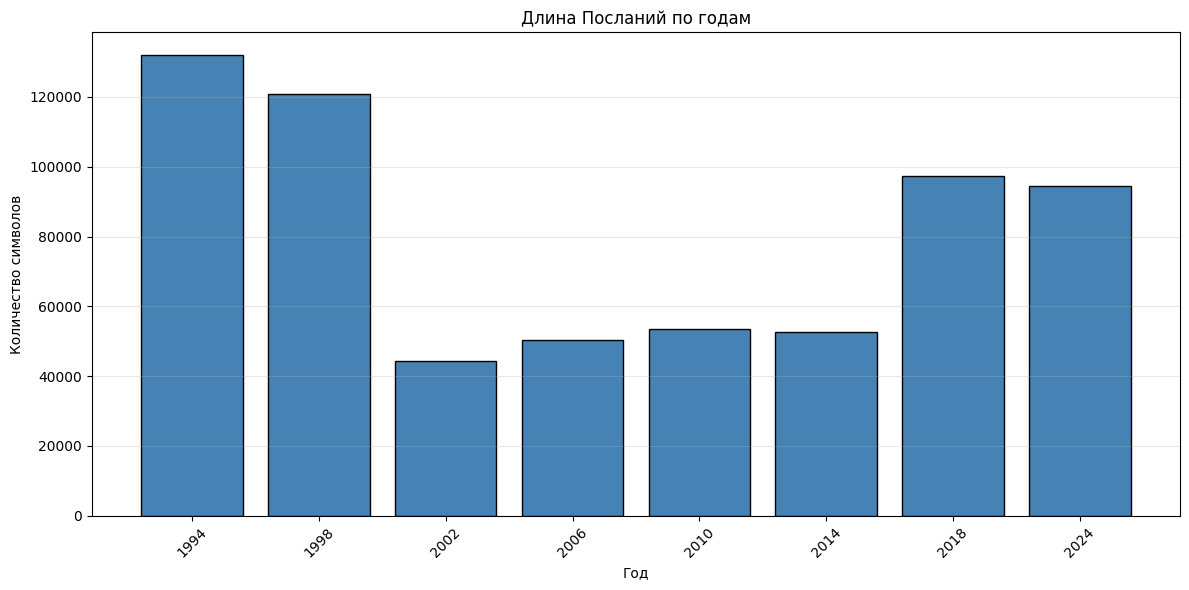

In [23]:
import matplotlib.pyplot as plt

years = sorted(corpus.keys())
lengths = [len(corpus[y]) for y in years]

plt.figure(figsize=(12, 6))
plt.bar(years, lengths, color='steelblue', edgecolor='black')
plt.xlabel('Год')
plt.ylabel('Количество символов')
plt.title('Длина Посланий по годам')
plt.xticks(years, rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
corpus_lemmas = {}

for year, text in corpus.items():
    toks = [t.text.lower() for t in tokenize(text) if t.text.lower().isalnum()]
    lems = [morph.parse(t)[0].normal_form for t in toks if t not in stop_words]
    corpus_lemmas[year] = Counter(lems)

# Пример: топ-20 по 1994
print("1994 топ-20:", corpus_lemmas["1994"].most_common(20))

1994 топ-10: [('государство', 134), ('россия', 134), ('власть', 111), ('российский', 108), ('должный', 107), ('государственный', 105), ('федеральный', 87), ('право', 76), ('реформа', 73), ('федерация', 72)]


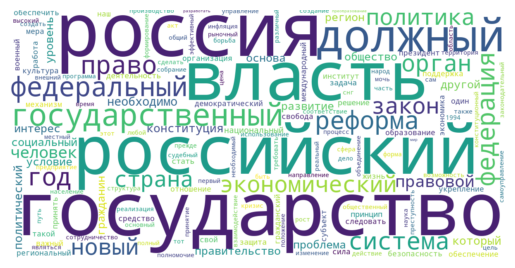

In [28]:
from wordcloud import WordCloud

freqs = corpus_lemmas["1994"]

wc = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=150,
    colormap='viridis',
    random_state=42,      # фиксируем, чтобы картинка была воспроизводимой
).generate_from_frequencies(freqs)

plt.imshow(wc, interpolation='bilinear')
plt.axis("off")
plt.margins(x=0, y=0)
plt.show()

### Практика. Сравнение годов

1. Для каждого года вычислите отношение уникальных лемм ко всем леммам в послании.
> Type-Token Ratio (TTR) — это показатель лексического разнообразия текста в лингвистике, который показывает, насколько богат словарный запас и как часто в тексте повторяются слова.
2. Найдите 5 общих самых частотных слов для всех годов.
3. Найдите слова, которые есть в топе 1994, но нет в топе 2024, и наоборот.